# Student At-Risk Identification: Logistic Regression (refactored)

IT3091 Machine Learning | Group 2026-AI-53

**Objective:** Train and evaluate Logistic Regression classifiers on the UCI Student Performance datasets (Mathematics and Portuguese) to identify students at risk of poor academic performance, show what tuning changes, and interpret what the model learned.

**Methodology (unchanged from the original notebook):**
- Target: **At-Risk = 1 when `G3 < 10`**, otherwise Not-At-Risk = 0.
- Inputs: every column except `G1`, `G2`, `G3`, so grades are never used to predict grades.
- Mathematics and Portuguese are modelled **separately**.
- Stratified 80/20 split, `random_state=42`.
- Preprocessing: median imputation and `StandardScaler` for numeric columns, most-frequent imputation and one-hot encoding for categorical columns, all inside a `Pipeline`.
- Baseline: `LogisticRegression(max_iter=2000, random_state=42)`. Tuning: `GridSearchCV` over `C` and `class_weight`, 5-fold stratified CV, scored by F1, on the training data only.

**Workflow:** Step 1 Setup and loading, Step 2 EDA, Step 3 Target and features, Step 4 Split and preprocessing, Step 5 Baseline, Step 6 Tuning, Step 7 Tuned evaluation, Step 8 Baseline versus tuned, Step 9 Coefficients, Step 10 Final results.

Every conclusion printed in Steps 5 to 10 is computed from the current run, so it updates if the notebook is re-run.

## Step 1: Setup and data loading

- **What are we doing?** Importing every library once, defining all settings and paths in one cell, and loading both CSV files once.
- **Why?** One configuration cell stops the seed, paths and column lists from drifting between cells, and loading once guarantees every later step uses identical data.
- **What does the code produce?** The shape and column check for each dataset.
- **How to interpret it?** Both files should have 33 columns with identical names. The Portuguese file has more rows.
- **What happens next?** Step 2 inspects data quality and distributions.

In [27]:
import seaborn as sns

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- Experiment settings (the only place these are defined) ----
RANDOM_STATE = 42           # same seed for the split, CV folds and model
TEST_SIZE = 0.20
CV_SPLITS = 5
TARGET_COLUMN = "G3"
RISK_THRESHOLD = 10         # G3 below this value means At-Risk
EXCLUDED_FEATURES = ["G1", "G2", "G3"]    # grades are never used as predictors
SUBJECTS = ["Mathematics", "Portuguese"]
FILE_NAMES = {"Mathematics": "student-mat.csv", "Portuguese": "student-por.csv"}
CLASS_NAMES = ["Not-At-Risk", "At-Risk"]
METRICS = ["Accuracy", "At-Risk Precision", "At-Risk Recall", "At-Risk F1", "ROC-AUC"]
SAVE_OUTPUTS = True         # set False to skip writing models and CSV reports

# ---- Paths (the only place these are defined) ----
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif not (ROOT / "data" / "raw").exists() and (ROOT / "student-risk-intelligence" / "data" / "raw").exists():
    ROOT = ROOT / "student-risk-intelligence"

DATA_DIR = ROOT / "data" / "raw"
MODEL_DIR = ROOT / "notebooks" / "models"
REPORT_DIR = ROOT / "notebooks" / "reports"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

print("Project root:", ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())

Project root: C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project
Data directory: C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\data\raw


In [3]:
# Load each CSV once. The UCI files are semicolon separated.
missing_files = [DATA_DIR / FILE_NAMES[s] for s in SUBJECTS if not (DATA_DIR / FILE_NAMES[s]).exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing dataset file(s):\n" + "\n".join(str(p) for p in missing_files)
        + "\nOpen the notebook from the project folder or update ROOT above."
    )

raw = {s: pd.read_csv(DATA_DIR / FILE_NAMES[s], sep=";") for s in SUBJECTS}

for s, df in raw.items():
    print(f"{s}: {df.shape[0]} rows x {df.shape[1]} columns")

print("\nColumns identical in both files:",
      raw["Mathematics"].columns.tolist() == raw["Portuguese"].columns.tolist())
print("\nColumns:", raw["Mathematics"].columns.tolist())

Mathematics: 395 rows x 33 columns
Portuguese: 649 rows x 33 columns

Columns identical in both files: True

Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


## Step 2: Data understanding and exploratory data analysis

- **What are we doing?** Inspecting sample records, data types, statistics, data quality, class balance, distributions, and correlations.
- **Why?** EDA shows whether the classes are imbalanced (which makes accuracy misleading), and whether predictors are strongly correlated with each other. That matters for Logistic Regression, because correlated predictors share coefficient weight. These charts describe the data and do not prove that any feature causes risk.
- **What does the code produce?** A quality table, sample rows, class balance with the `G3` distribution, numeric distributions, correlation with the At-Risk label, correlation between predictors, and at-risk rate by category.
- **How to interpret it?** The printed "Observation" lines under the charts are computed from the data.
- **What happens next?** Step 3 formally defines the target and predictors.

In [4]:
# Data quality summary and a first look at the records
quality = pd.DataFrame({
    s: {
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Numeric columns": df.select_dtypes(include="number").shape[1],
        "Categorical columns": df.select_dtypes(exclude="number").shape[1],
        "Missing values": int(df.isnull().sum().sum()),
        "Duplicate rows": int(df.duplicated().sum()),
        "Distinct G3 values": df["G3"].nunique(),
    }
    for s, df in raw.items()
})
display(quality)

for s, df in raw.items():
    print(f"\n{s}: first 3 records")
    display(df.head(3))
    print(f"{s}: descriptive statistics (numeric columns)")
    display(df.describe().T.round(2))

,Mathematics,Portuguese
Rows,395,649
Columns,33,33
Numeric columns,16,16
Categorical columns,17,17
Missing values,0,0
Duplicate rows,0,0
Distinct G3 values,18,17



Mathematics: first 3 records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10


Mathematics: descriptive statistics (numeric columns)


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0



Portuguese: first 3 records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12


Portuguese: descriptive statistics (numeric columns)


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


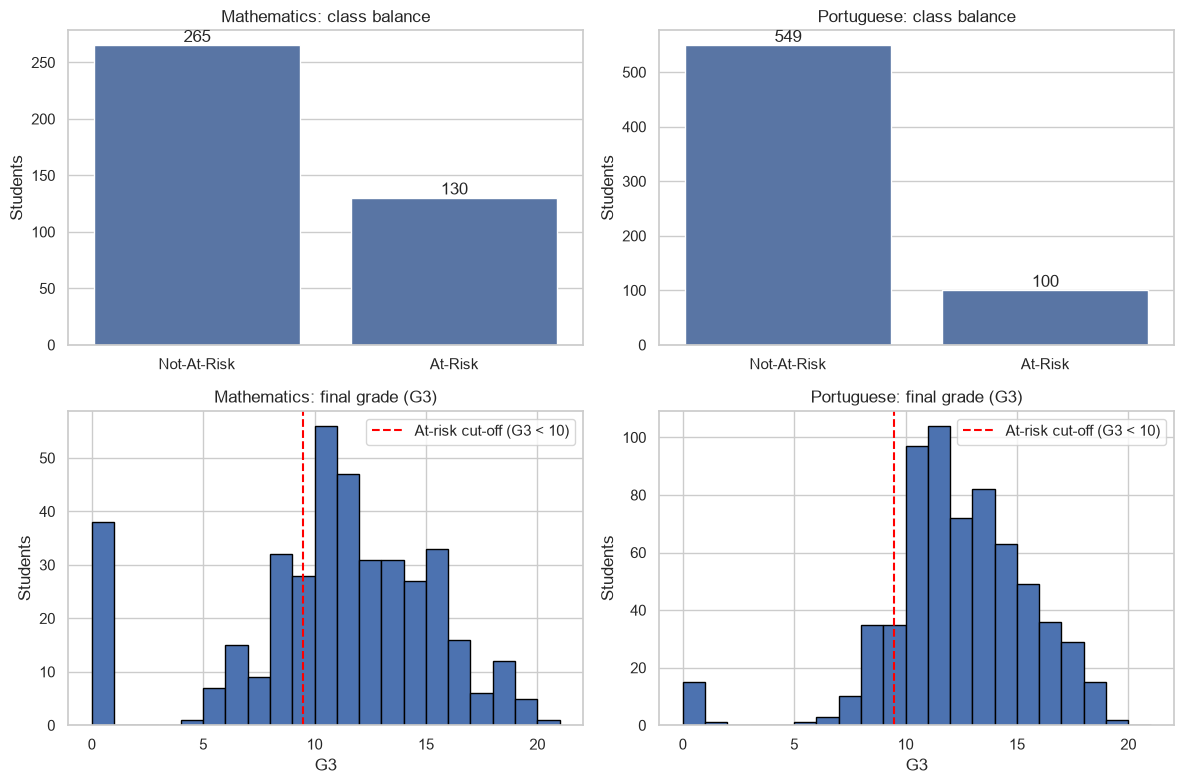

Observation: Mathematics: 32.9% of students are At-Risk.
Observation: Portuguese: 15.4% of students are At-Risk.
The At-Risk class is the minority in both subjects, so Precision, Recall and F1 for At-Risk matter more than Accuracy.


In [5]:
# Class balance and the G3 distribution relative to the at-risk cut-off
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, s in enumerate(SUBJECTS):
    df = raw[s]
    labels = (df[TARGET_COLUMN] < RISK_THRESHOLD).map({True: "At-Risk", False: "Not-At-Risk"})
    sns.countplot(x=labels, order=CLASS_NAMES, ax=axes[0, col])
    axes[0, col].set_title(f"{s}: class balance")
    axes[0, col].set_xlabel("")
    axes[0, col].set_ylabel("Students")
    for container in axes[0, col].containers:
        axes[0, col].bar_label(container)

    axes[1, col].hist(df[TARGET_COLUMN], bins=range(0, 22), edgecolor="black")
    axes[1, col].axvline(RISK_THRESHOLD - 0.5, color="red", linestyle="--", label=f"At-risk cut-off (G3 < {RISK_THRESHOLD})")
    axes[1, col].set_title(f"{s}: final grade (G3)")
    axes[1, col].set_xlabel("G3")
    axes[1, col].set_ylabel("Students")
    axes[1, col].legend()
plt.tight_layout()
plt.show()

for s in SUBJECTS:
    share = (raw[s][TARGET_COLUMN] < RISK_THRESHOLD).mean() * 100
    print(f"Observation: {s}: {share:.1f}% of students are At-Risk.")
print("The At-Risk class is the minority in both subjects, so Precision, Recall and F1 for At-Risk matter more than Accuracy.")

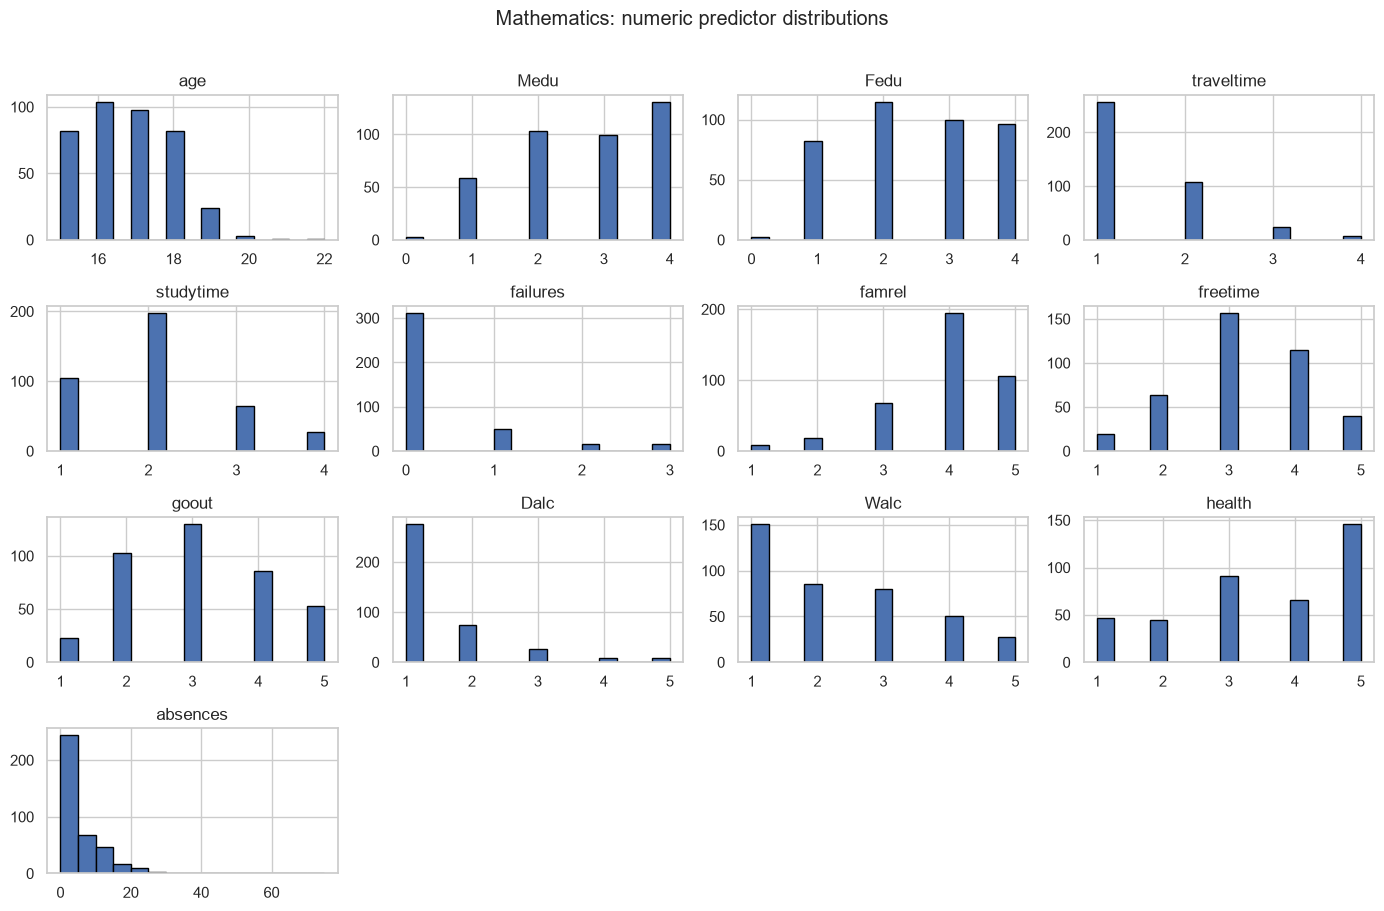

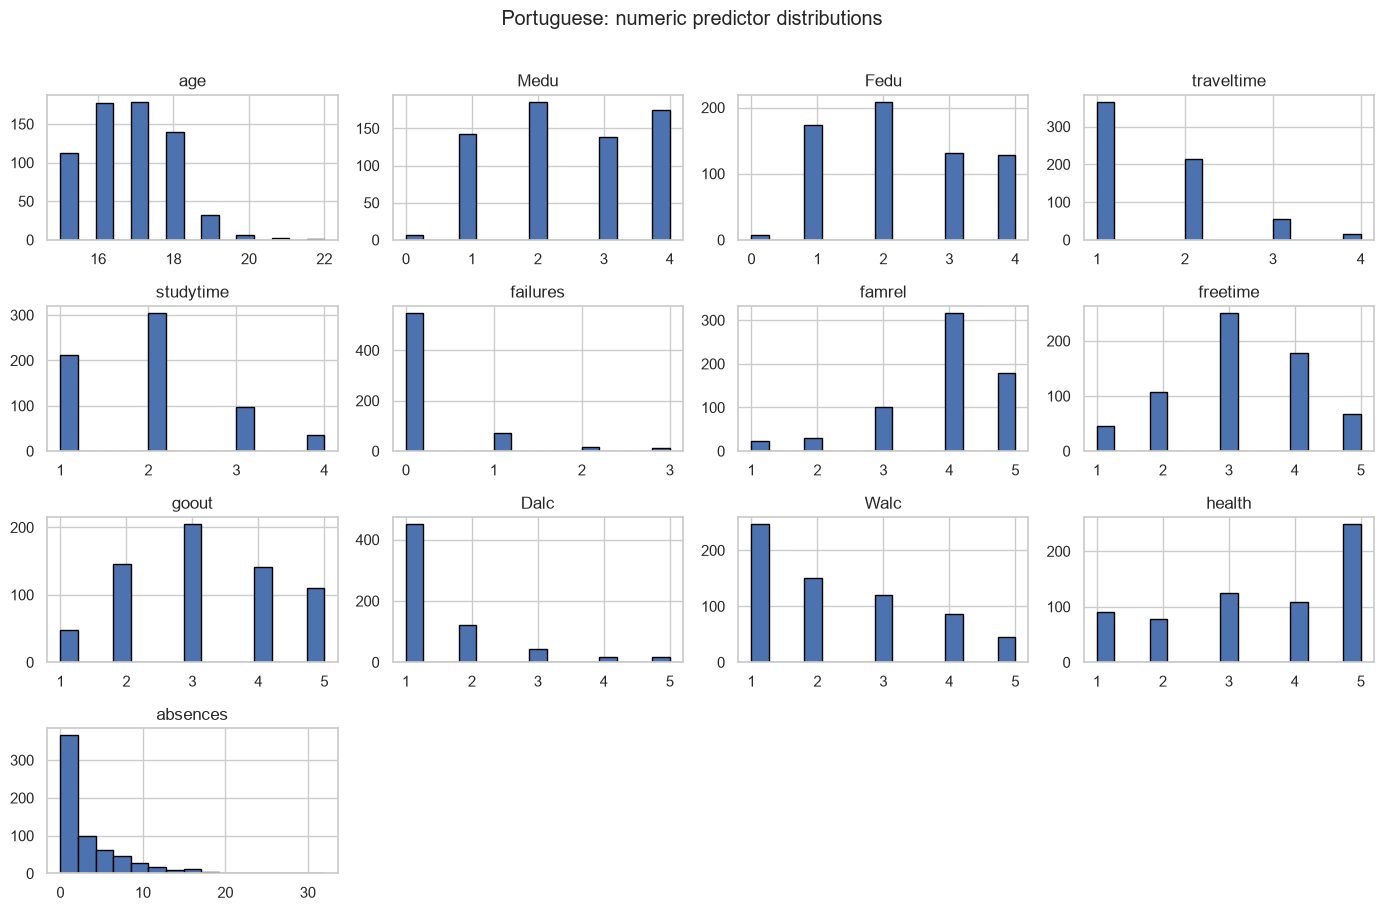

Observation guide: most numeric predictors are small ordinal scales. Absences is the clearly skewed one.


In [6]:
# Distributions of the numeric predictors (grades excluded because they are not model inputs)
for s in SUBJECTS:
    numeric_predictors = [c for c in raw[s].select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    raw[s][numeric_predictors].hist(figsize=(14, 9), bins=15, edgecolor="black", layout=(4, 4))
    plt.suptitle(f"{s}: numeric predictor distributions", y=1.01)
    plt.tight_layout()
    plt.show()
print("Observation guide: most numeric predictors are small ordinal scales. Absences is the clearly skewed one.")

Observation: Mathematics: strongest linear associations with risk: failures (+0.34), goout (+0.18), age (+0.18)
Observation: Portuguese: strongest linear associations with risk: failures (+0.38), studytime (-0.17), Fedu (-0.15)


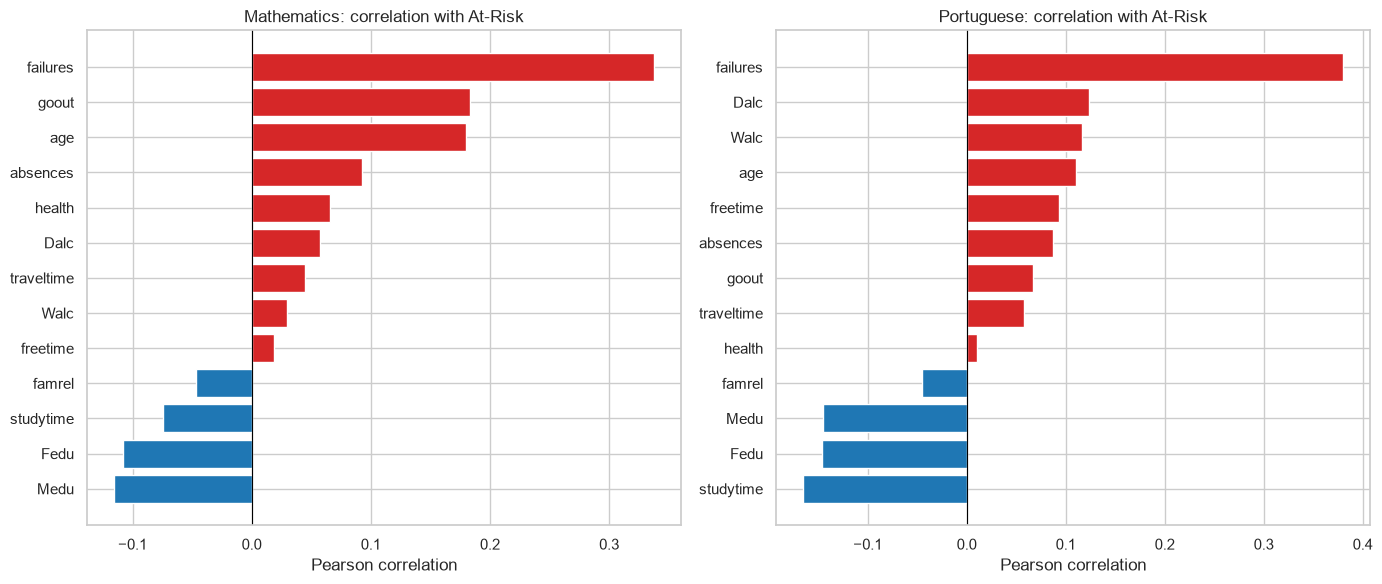

In [7]:
# Association of each numeric predictor with the At-Risk label (association, not causation)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, s in zip(axes, SUBJECTS):
    df = raw[s]
    risk = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    numeric_predictors = [c for c in df.select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    corr = df[numeric_predictors].corrwith(risk).sort_values()
    ax.barh(corr.index, corr.values, color=["tab:red" if v > 0 else "tab:blue" for v in corr.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{s}: correlation with At-Risk")
    ax.set_xlabel("Pearson correlation")
    top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(3)
    print(f"Observation: {s}: strongest linear associations with risk: "
          + ", ".join(f"{k} ({v:+.2f})" for k, v in top.items()))
plt.tight_layout()
plt.show()

Observation: Mathematics: predictor pairs with |correlation| >= 0.5: Medu/Fedu (+0.62), Dalc/Walc (+0.65)
Observation: Portuguese: predictor pairs with |correlation| >= 0.5: Medu/Fedu (+0.65), Dalc/Walc (+0.62)


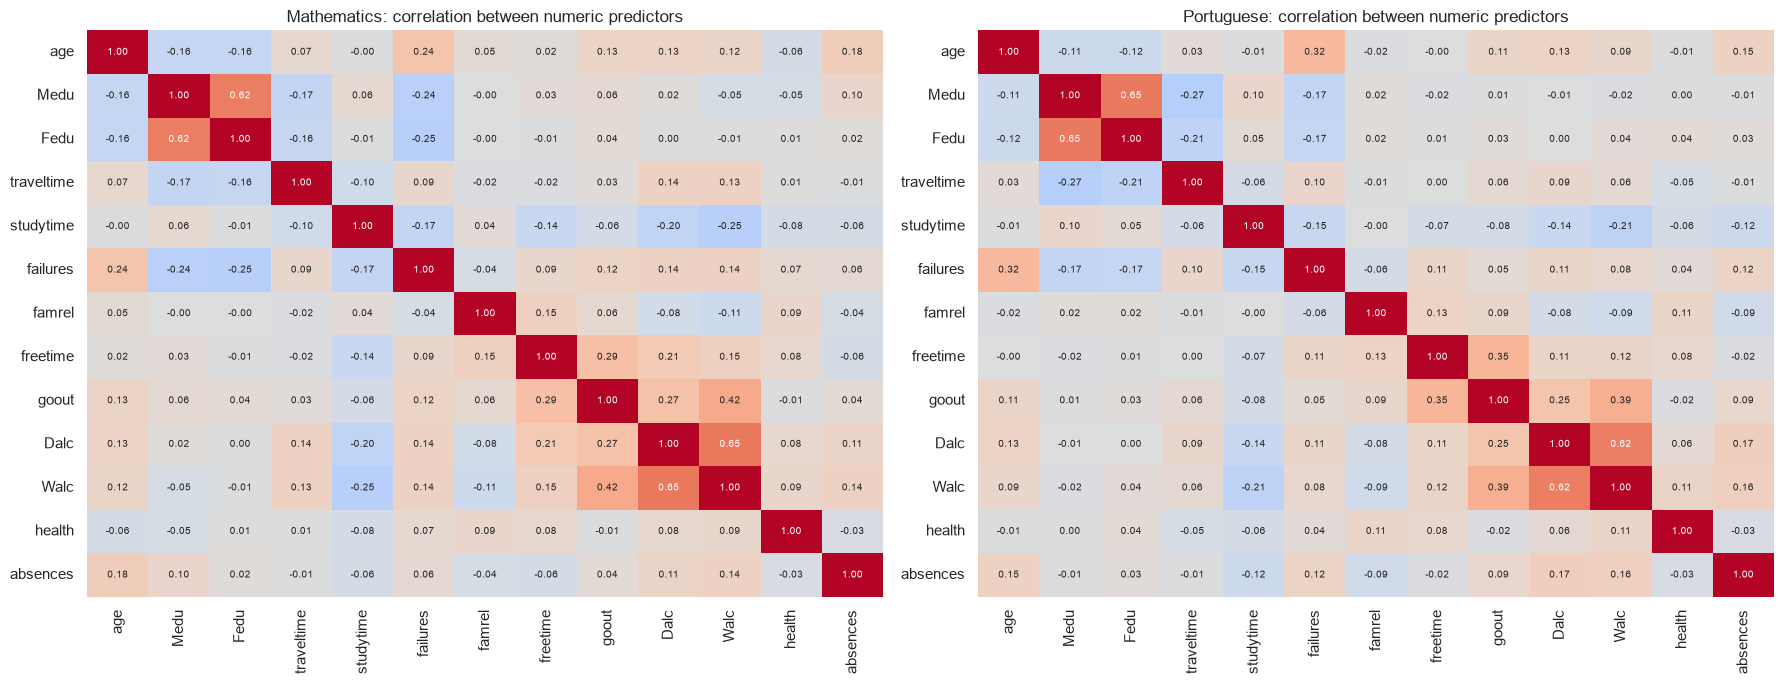

In [8]:
# Correlation between numeric predictors (collinearity makes coefficients harder to interpret)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, s in zip(axes, SUBJECTS):
    numeric_predictors = [c for c in raw[s].select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    corr = raw[s][numeric_predictors].corr()
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar=False)
    ax.set_title(f"{s}: correlation between numeric predictors")
    pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.5]
    print(f"Observation: {s}: predictor pairs with |correlation| >= 0.5: "
          + (", ".join(f"{a}/{b} ({v:+.2f})" for a, b, v in pairs) if pairs else "none"))
plt.tight_layout()
plt.show()

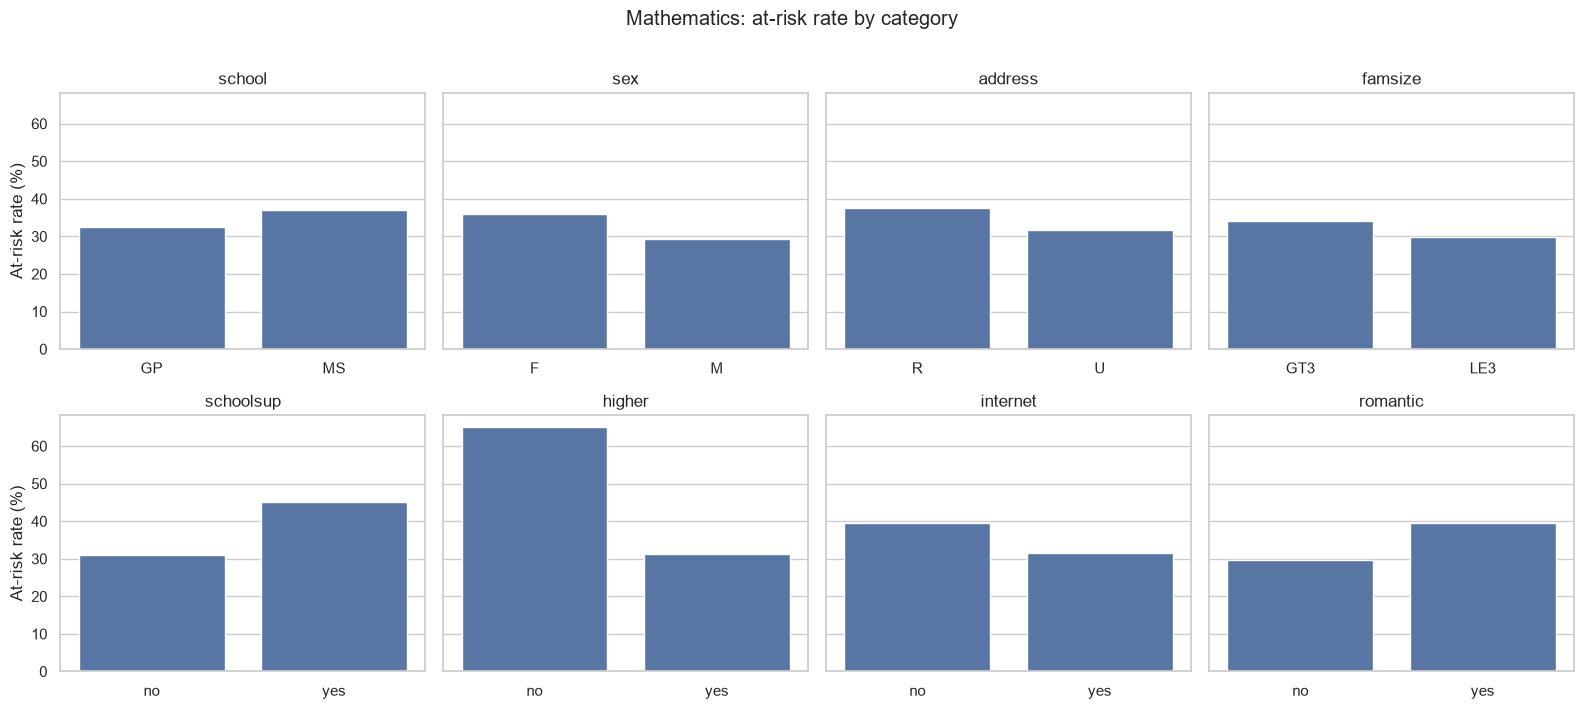

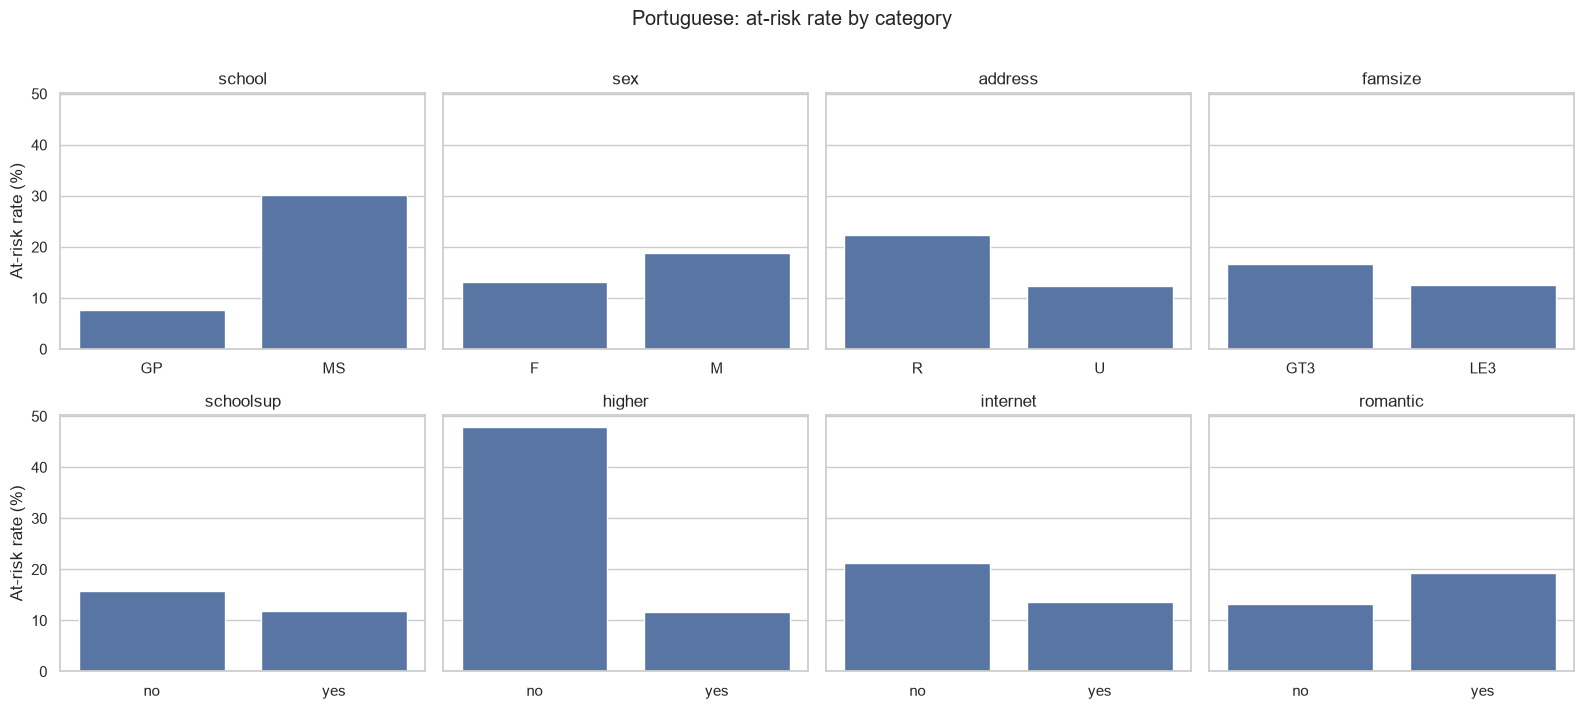

Observation guide: a large gap between categories means the groups differ in risk. It does not show why.


In [9]:
# At-risk rate by category for eight categorical predictors
cat_cols = ["school", "sex", "address", "famsize", "schoolsup", "higher", "internet", "romantic"]
for s in SUBJECTS:
    df = raw[s].copy()
    df["at_risk"] = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
    for ax, name in zip(axes.flat, cat_cols):
        rate = df.groupby(name)["at_risk"].mean().mul(100)
        sns.barplot(x=rate.index, y=rate.values, ax=ax)
        ax.set_title(name)
        ax.set_xlabel("")
        ax.set_ylabel("At-risk rate (%)")
    fig.suptitle(f"{s}: at-risk rate by category", y=1.01)
    plt.tight_layout()
    plt.show()
print("Observation guide: a large gap between categories means the groups differ in risk. It does not show why.")

## Step 3: Target definition and feature preparation

- **What are we doing?** Creating the binary target and removing `G1`, `G2` and `G3` from the predictors.
- **Why?** `G3` defines the label, and `G1` and `G2` are earlier grades in the same course. Using them would let the model infer risk from grades, which defeats early identification. All other columns stay as predictors.
- **What does the code produce?** One `prepare_features` function, the feature and target counts, leakage checks, and the numeric and categorical column lists.
- **How to interpret it?** Both leakage checks must print `True`. The predictor count should be the original column count minus three.
- **What happens next?** Step 4 splits the data and defines the preprocessing pipeline.

In [10]:
def prepare_features(df):
    """Return predictors X and the At-Risk target y (1 = G3 below the cut-off)."""
    y = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    X = df.drop(columns=EXCLUDED_FEATURES).copy()    # leakage control: no grade columns
    return X, y

features, target = {}, {}
for s in SUBJECTS:
    features[s], target[s] = prepare_features(raw[s])

feature_summary = pd.DataFrame({
    s: {
        "Predictor columns": features[s].shape[1],
        "Numeric predictors": features[s].select_dtypes(include="number").shape[1],
        "Categorical predictors": features[s].select_dtypes(exclude="number").shape[1],
        "At-Risk students": int(target[s].sum()),
        "Not-At-Risk students": int((1 - target[s]).sum()),
        "Grade columns excluded from inputs": all(c not in features[s].columns for c in EXCLUDED_FEATURES),
        "Target values": str([int(v) for v in sorted(target[s].unique())]),
    }
    for s in SUBJECTS
})
display(feature_summary)

print("Numeric predictors:", features["Mathematics"].select_dtypes(include="number").columns.tolist())
print("\nCategorical predictors:", features["Mathematics"].select_dtypes(exclude="number").columns.tolist())

,Mathematics,Portuguese
Predictor columns,30,30
Numeric predictors,13,13
Categorical predictors,17,17
At-Risk students,130,100
Not-At-Risk students,265,549
Grade columns excluded from inputs,True,True
Target values,"[0, 1]","[0, 1]"


Numeric predictors: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical predictors: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


## Step 4: Train-test split and preprocessing

- **What are we doing?** Splitting each subject into 80% training and 20% test data (stratified), and defining one preprocessing-plus-model pipeline.
- **Why?** Stratification keeps the At-Risk share similar in both parts. Logistic Regression needs numeric input and works better with scaled features, so numeric columns get median imputation and standardisation, and categorical columns get most-frequent imputation and one-hot encoding. Putting this inside the `Pipeline` means it is learned from training data only, and refitted inside each CV fold during tuning, so the test set never influences it.
- **What does the code produce?** A `data` dictionary with each subject's split, a split summary, and the `build_lr_pipeline` function plus evaluation and plotting helpers.
- **How to interpret it?** Training and test At-Risk percentages should be almost equal.
- **What happens next?** Step 5 trains the baseline on the training data and scores it once on the test data.

In [11]:
# Stratified split, identical for the baseline and the tuned model
data = {}
for s in SUBJECTS:
    X_train, X_test, y_train, y_test = train_test_split(
        features[s], target[s],
        test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=target[s],
    )
    data[s] = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test}

split_summary = pd.DataFrame({
    s: {
        "Training records": len(d["X_train"]),
        "Test records": len(d["X_test"]),
        "Training At-Risk (%)": round(d["y_train"].mean() * 100, 2),
        "Test At-Risk (%)": round(d["y_test"].mean() * 100, 2),
        "Test At-Risk students": int(d["y_test"].sum()),
    }
    for s, d in data.items()
})
display(split_summary)

,Mathematics,Portuguese
Training records,316.00,519.00
Test records,79.00,130.00
Training At-Risk (%),32.91,15.41
Test At-Risk (%),32.91,15.38
Test At-Risk students,26.00,20.00


In [12]:
def build_lr_pipeline(X_train):
    """Preprocessing + Logistic Regression. Unfitted: every fit learns only from the data it is given."""
    numeric = X_train.select_dtypes(include="number").columns.tolist()
    categorical = X_train.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),                  # puts numeric coefficients on a per-standard-deviation scale
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])


def evaluate_model(model, X_test, y_test):
    """Score a fitted model on the held-out test set with the same definitions every time."""
    assert list(model.named_steps["classifier"].classes_) == [0, 1]   # column 1 of predict_proba is At-Risk
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "At-Risk Precision": precision_score(y_test, y_pred, zero_division=0),
        "At-Risk Recall": recall_score(y_test, y_pred, zero_division=0),
        "At-Risk F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob),
    }
    return {"metrics": metrics, "y_pred": y_pred, "y_prob": y_prob}


def plot_confusion_matrices(evaluations, title, cmap):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, s in zip(axes, SUBJECTS):
        cm = confusion_matrix(data[s]["y_test"], evaluations[s]["y_pred"], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        ax.set_title(f"{s}: {title}")
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")
    plt.tight_layout()
    plt.show()


def plot_roc_and_pr(evaluations, title):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for i, s in enumerate(SUBJECTS):
        y_test, prob = data[s]["y_test"], evaluations[s]["y_prob"]
        RocCurveDisplay.from_predictions(y_test, prob, name=s, ax=axes[i])
        axes[i].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
        axes[i].set_title(f"{s}: {title} ROC curve")
        PrecisionRecallDisplay.from_predictions(y_test, prob, name=s, ax=axes[2 + i])
        axes[2 + i].set_title(f"{s}: {title} precision-recall curve")
    plt.tight_layout()
    plt.show()


def describe_confusion(evaluations, label):
    """Plain-language reading of each confusion matrix, computed from the results."""
    for s in SUBJECTS:
        tn, fp, fn, tp = confusion_matrix(data[s]["y_test"], evaluations[s]["y_pred"], labels=[0, 1]).ravel()
        print(f"{label} {s}: detected {tp} of {tp + fn} at-risk students (recall {tp / (tp + fn):.0%}); "
              f"missed {fn}; flagged {fp} not-at-risk students unnecessarily.")

print("Pipeline and evaluation helpers defined.")

Pipeline and evaluation helpers defined.


## Step 5: Baseline Logistic Regression model (before tuning)

- **What are we doing?** Training Logistic Regression with the original baseline settings: `LogisticRegression(max_iter=2000, random_state=42)`. The other settings are scikit-learn defaults, including `C=1.0`, no class weights and the `lbfgs` solver.
- **Why?** Without a baseline we cannot tell whether tuning helps. Logistic Regression computes a weighted score for each student, then turns it into a probability with the sigmoid function:

\[
z = \theta_0 + \theta_1x_1 + \cdots + \theta_nx_n, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}
\]

  A student is predicted At-Risk when the probability is at least 0.5. The default `C=1.0` applies moderate L2 regularisation, which limits how large coefficients can grow.
- **What does the code produce?** A fitted baseline model per subject, a metrics table, confusion matrices, ROC and precision-recall curves.
- **How to interpret it?** Precision is the share of flagged students who are truly at risk. Recall is the share of truly at-risk students that were found. F1 balances the two. ROC-AUC measures how well probabilities rank students regardless of threshold. A **false negative** is an at-risk student who was missed, which is the costly error for early support. A **false positive** is an unnecessary follow-up.
- **What happens next?** Step 6 searches for better settings using training data only.

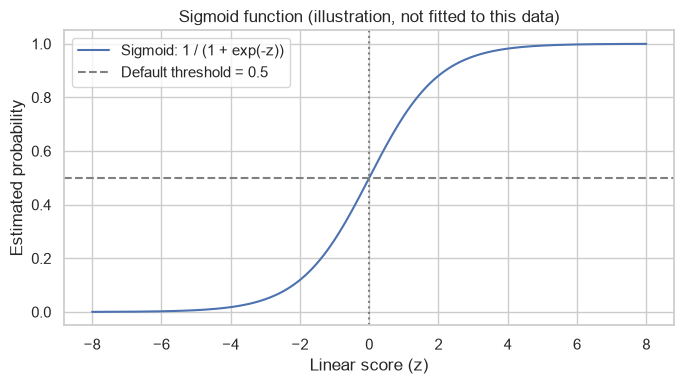

In [13]:
# Educational illustration only: the sigmoid turns the linear score z into a probability
z_values = np.linspace(-8, 8, 300)
plt.figure(figsize=(7, 4))
plt.plot(z_values, 1 / (1 + np.exp(-z_values)), label="Sigmoid: 1 / (1 + exp(-z))")
plt.axhline(0.5, linestyle="--", color="gray", label="Default threshold = 0.5")
plt.axvline(0, linestyle=":", color="gray")
plt.xlabel("Linear score (z)")
plt.ylabel("Estimated probability")
plt.title("Sigmoid function (illustration, not fitted to this data)")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# Fit on training data only, then score once on the held-out test set
baseline_models, baseline_eval = {}, {}
for s in SUBJECTS:
    model = build_lr_pipeline(data[s]["X_train"])
    model.fit(data[s]["X_train"], data[s]["y_train"])
    baseline_models[s] = model
    baseline_eval[s] = evaluate_model(model, data[s]["X_test"], data[s]["y_test"])

    print(f"\n{'=' * 50}\n{s}: baseline classification report (test set)\n{'=' * 50}")
    print(classification_report(data[s]["y_test"], baseline_eval[s]["y_pred"],
                                target_names=CLASS_NAMES, zero_division=0))

baseline_df = pd.DataFrame([{"Dataset": s, **baseline_eval[s]["metrics"]} for s in SUBJECTS])
print("Baseline test metrics")
display(baseline_df.round(4))


Mathematics: baseline classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.72      0.89      0.80        53
     At-Risk       0.57      0.31      0.40        26

    accuracy                           0.70        79
   macro avg       0.65      0.60      0.60        79
weighted avg       0.67      0.70      0.67        79


Portuguese: baseline classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.86      0.97      0.91       110
     At-Risk       0.50      0.15      0.23        20

    accuracy                           0.85       130
   macro avg       0.68      0.56      0.57       130
weighted avg       0.81      0.85      0.81       130

Baseline test metrics


,Dataset,Accuracy,At-Risk Precision,At-Risk Recall,At-Risk F1,ROC-AUC,Average Precision
0,Mathematics,0.6962,0.5714,0.3077,0.4000,0.7148,0.5841
1,Portuguese,0.8462,0.5000,0.1500,0.2308,0.7659,0.3385


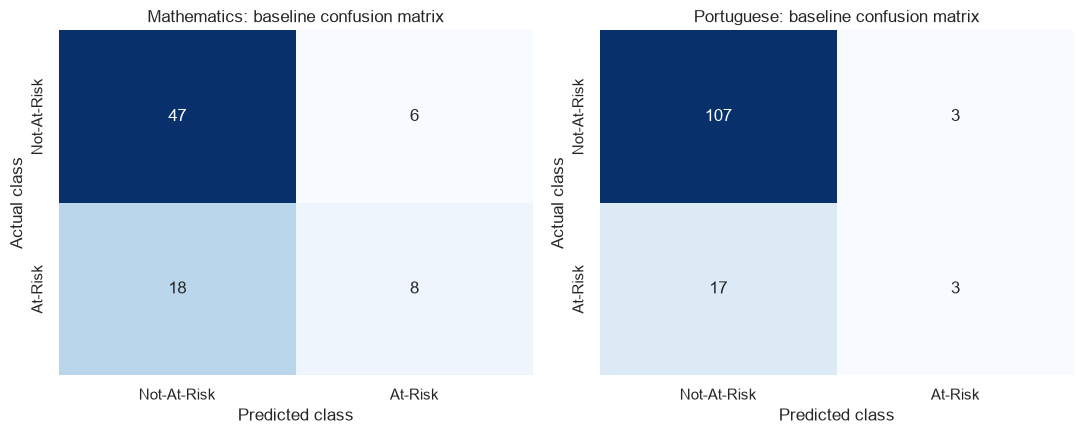

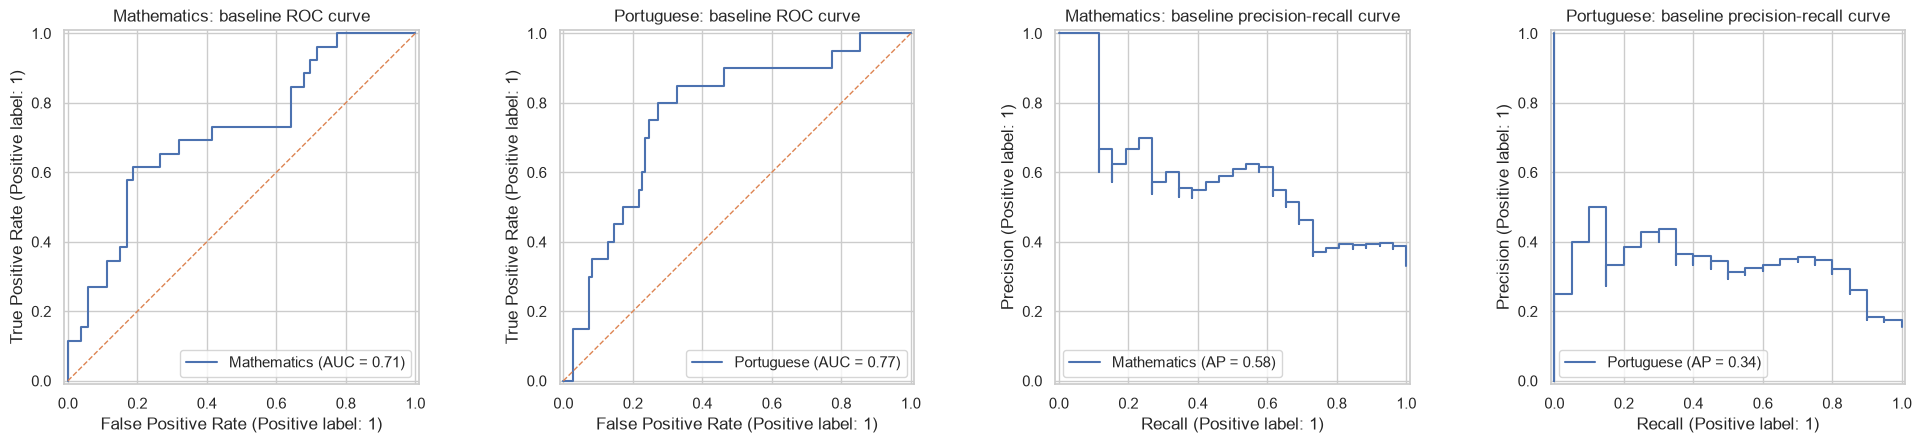

Baseline Mathematics: detected 8 of 26 at-risk students (recall 31%); missed 18; flagged 6 not-at-risk students unnecessarily.
Baseline Portuguese: detected 3 of 20 at-risk students (recall 15%); missed 17; flagged 3 not-at-risk students unnecessarily.


In [15]:
plot_confusion_matrices(baseline_eval, "baseline confusion matrix", "Blues")
plot_roc_and_pr(baseline_eval, "baseline")
describe_confusion(baseline_eval, "Baseline")

## Step 6: Hyperparameter tuning

- **What are we doing?** Running `GridSearchCV` over 10 combinations of two hyperparameters, using 5-fold stratified cross-validation on the **training data only**. The score used to choose is **F1 for the At-Risk class**.
- **Which parameters?**
  - `C` (0.01, 0.1, 1, 10, 100): the inverse of regularisation strength. A small `C` shrinks coefficients strongly and gives a simpler model. A large `C` lets the model fit the training data more closely.
  - `class_weight` (`None`, `"balanced"`): with `"balanced"`, mistakes on the rarer At-Risk class are penalised more, which usually raises recall and lowers precision.
  - The solver stays at the default `lbfgs` and `max_iter=2000`, as in the original notebook. It is not tuned.
- **Why F1?** It rewards finding at-risk students without flagging too many others. The test set is not used in this step.
- **What does the code produce?** The best parameters, the best mean CV F1, the top configurations, and the CV F1 of the baseline settings on the same folds.
- **How to interpret it?** CV F1 values come from training folds and are not test results. The default settings (`C=1`, `None`) are part of the grid, so the best CV F1 can never be below the baseline's CV F1. If the best `C` sits at an edge of the grid, a value beyond the edge was never tested.
- **What happens next?** Step 7 evaluates the selected model on the same test set used for the baseline.

In [16]:
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
}

grids, tuning_rows = {}, []
for s in SUBJECTS:
    X_train, y_train = data[s]["X_train"], data[s]["y_train"]

    grid = GridSearchCV(build_lr_pipeline(X_train), param_grid,
                        scoring="f1", cv=cv, n_jobs=1, refit=True, error_score="raise")
    grid.fit(X_train, y_train)          # training data only
    grids[s] = grid

    # Baseline settings scored on the same folds, so the two CV F1 values are comparable
    baseline_cv_f1 = cross_val_score(build_lr_pipeline(X_train), X_train, y_train,
                                     cv=cv, scoring="f1").mean()
    tuning_rows.append({
        "Dataset": s,
        "Best C": grid.best_params_["classifier__C"],
        "Class Weight": grid.best_params_["classifier__class_weight"],
        "Best CV F1": grid.best_score_,
        "Baseline CV F1 (C=1, no class weight)": baseline_cv_f1,
    })

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df.round(4))

for s in SUBJECTS:
    res = pd.DataFrame(grids[s].cv_results_).sort_values("rank_test_score").head(5)
    top = pd.DataFrame({
        "Rank": res["rank_test_score"],
        "C": res["param_classifier__C"],
        "Class weight": res["param_classifier__class_weight"],
        "Mean CV F1": res["mean_test_score"],
        "Std CV F1": res["std_test_score"],
    })
    print(f"\n{s}: top 5 configurations by mean CV F1")
    display(top.round(4))

,Dataset,Best C,Class Weight,Best CV F1,"Baseline CV F1 (C=1, no class weight)"
0,Mathematics,0.10,balanced,0.4895,0.4011
1,Portuguese,0.01,balanced,0.5082,0.3700



Mathematics: top 5 configurations by mean CV F1


,Rank,C,Class weight,Mean CV F1,Std CV F1
3,1,0.10,balanced,0.4895,0.0555
1,2,0.01,balanced,0.4840,0.0671
7,3,10.00,balanced,0.4821,0.0405
9,3,100.00,balanced,0.4821,0.0405
5,5,1.00,balanced,0.4780,0.0438



Portuguese: top 5 configurations by mean CV F1


,Rank,C,Class weight,Mean CV F1,Std CV F1
1,1,0.01,balanced,0.5082,0.0731
3,2,0.10,balanced,0.4623,0.0592
5,3,1.00,balanced,0.4395,0.0463
7,4,10.00,balanced,0.4271,0.0572
9,5,100.00,balanced,0.4255,0.0592


In [17]:
c_values = param_grid["classifier__C"]
for s in SUBJECTS:
    row = tuning_df.set_index("Dataset").loc[s]
    gain = row["Best CV F1"] - row["Baseline CV F1 (C=1, no class weight)"]
    print(f"Observation: {s}: best CV F1 {row['Best CV F1']:.4f} versus {row['Baseline CV F1 (C=1, no class weight)']:.4f} "
          f"for the baseline settings (difference {gain:+.4f}). Selected C={row['Best C']}, class_weight={row['Class Weight']}.")
    if row["Best C"] in (min(c_values), max(c_values)):
        print(f"  The selected C={row['Best C']} is at the edge of the grid, so a more extreme value was not tested.")

Observation: Mathematics: best CV F1 0.4895 versus 0.4011 for the baseline settings (difference +0.0884). Selected C=0.1, class_weight=balanced.
Observation: Portuguese: best CV F1 0.5082 versus 0.3700 for the baseline settings (difference +0.1382). Selected C=0.01, class_weight=balanced.
  The selected C=0.01 is at the edge of the grid, so a more extreme value was not tested.


## Step 7: Evaluate the tuned model

- **What are we doing?** Taking the best pipeline from each grid search (already refitted on the full training set) and scoring it on the held-out test set.
- **Why?** The test set has been used for nothing except the baseline score, so it is a fair and identical yardstick for both models. The metric function is the same one used in Step 5.
- **What does the code produce?** Tuned test metrics, classification reports, confusion matrices, ROC and precision-recall curves.
- **How to interpret it?** These are test results. Do not compare them with the CV F1 values from Step 6, which come from different data.
- **What happens next?** Step 8 places baseline and tuned results side by side.

In [18]:
tuned_models = {s: grids[s].best_estimator_ for s in SUBJECTS}
tuned_eval = {s: evaluate_model(tuned_models[s], data[s]["X_test"], data[s]["y_test"]) for s in SUBJECTS}

for s in SUBJECTS:
    print(f"\n{'=' * 50}\n{s}: tuned classification report (test set)\n{'=' * 50}")
    print(classification_report(data[s]["y_test"], tuned_eval[s]["y_pred"],
                                target_names=CLASS_NAMES, zero_division=0))

tuned_df = pd.DataFrame([{"Dataset": s, **tuned_eval[s]["metrics"]} for s in SUBJECTS])
print("Tuned test metrics")
display(tuned_df.round(4))


Mathematics: tuned classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.82      0.68      0.74        53
     At-Risk       0.51      0.69      0.59        26

    accuracy                           0.68        79
   macro avg       0.67      0.69      0.67        79
weighted avg       0.72      0.68      0.69        79


Portuguese: tuned classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.92      0.84      0.88       110
     At-Risk       0.40      0.60      0.48        20

    accuracy                           0.80       130
   macro avg       0.66      0.72      0.68       130
weighted avg       0.84      0.80      0.82       130

Tuned test metrics


,Dataset,Accuracy,At-Risk Precision,At-Risk Recall,At-Risk F1,ROC-AUC,Average Precision
0,Mathematics,0.6835,0.5143,0.6923,0.5902,0.7315,0.6010
1,Portuguese,0.8000,0.4000,0.6000,0.4800,0.7900,0.3527


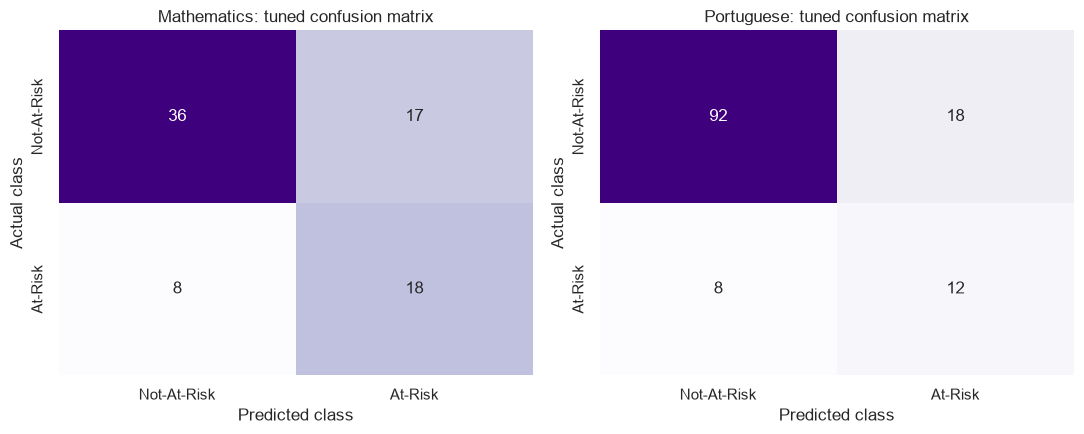

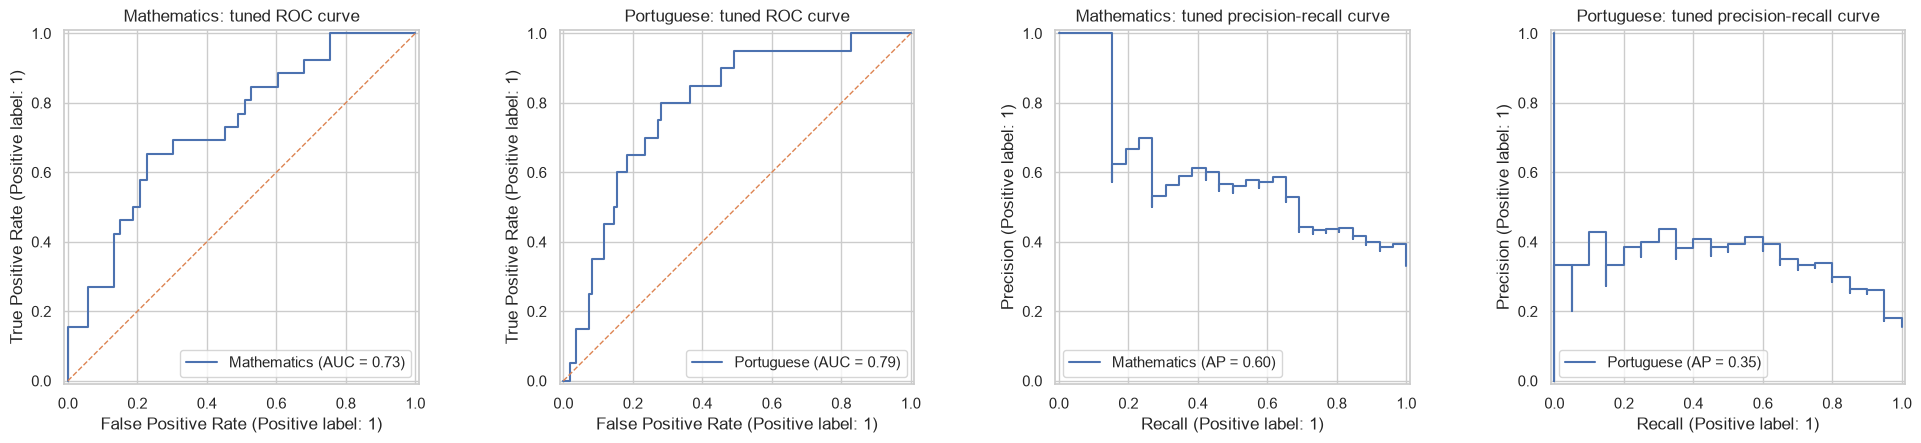

Tuned Mathematics: detected 18 of 26 at-risk students (recall 69%); missed 8; flagged 17 not-at-risk students unnecessarily.
Tuned Portuguese: detected 12 of 20 at-risk students (recall 60%); missed 8; flagged 18 not-at-risk students unnecessarily.


In [19]:
plot_confusion_matrices(tuned_eval, "tuned confusion matrix", "Purples")
plot_roc_and_pr(tuned_eval, "tuned")
describe_confusion(tuned_eval, "Tuned")

## Step 8: Compare baseline and tuned results

- **What are we doing?** Putting baseline and tuned test metrics side by side for each dataset.
- **Why?** Tuning is not guaranteed to help on unseen data. The comparison shows which metrics improved, which declined, and whether there is a trade-off such as higher recall at the cost of precision.
- **What does the code produce?** One table per dataset with the change in every metric, a grouped bar chart, and a computed summary.
- **How to interpret it?** Test sets are small, so one student changes recall by a visible amount. The summary prints how many at-risk students each test set holds.
- **What happens next?** Step 9 examines the coefficients of the fitted models.


Mathematics: baseline versus tuned (held-out test set)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.6962,0.6835,-0.0127
At-Risk Precision,0.5714,0.5143,-0.0571
At-Risk Recall,0.3077,0.6923,0.3846
At-Risk F1,0.4000,0.5902,0.1902
ROC-AUC,0.7148,0.7315,0.0167



Portuguese: baseline versus tuned (held-out test set)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.8462,0.80,-0.0462
At-Risk Precision,0.5000,0.40,-0.1000
At-Risk Recall,0.1500,0.60,0.4500
At-Risk F1,0.2308,0.48,0.2492
ROC-AUC,0.7659,0.79,0.0241


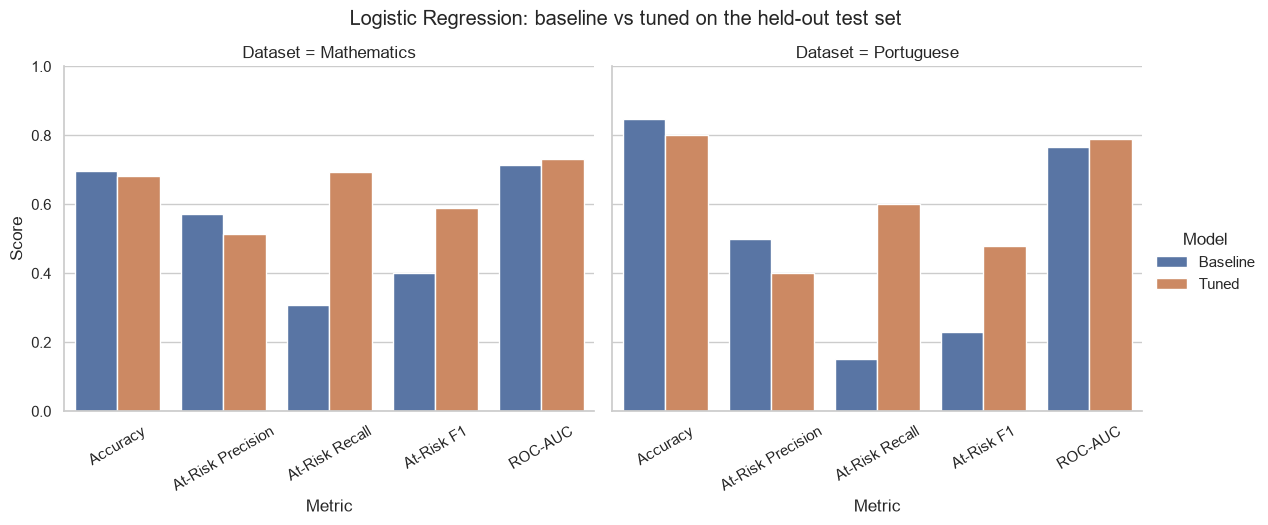

In [20]:
comparison_long = pd.concat([
    baseline_df.assign(Model="Baseline"),
    tuned_df.assign(Model="Tuned"),
], ignore_index=True)

comparison_tables = {}
for s in SUBJECTS:
    b = baseline_df.set_index("Dataset").loc[s, METRICS]
    t = tuned_df.set_index("Dataset").loc[s, METRICS]
    comparison_tables[s] = pd.DataFrame({"Baseline": b, "Tuned": t, "Change (Tuned - Baseline)": t - b})
    print(f"\n{s}: baseline versus tuned (held-out test set)")
    display(comparison_tables[s].round(4))

plot_df = comparison_long.melt(id_vars=["Dataset", "Model"], value_vars=METRICS,
                               var_name="Metric", value_name="Score")
g = sns.catplot(data=plot_df, kind="bar", x="Metric", y="Score", hue="Model",
                col="Dataset", height=4.5, aspect=1.3)
g.set(ylim=(0, 1))
g.set_xticklabels(rotation=30)
g.figure.suptitle("Logistic Regression: baseline vs tuned on the held-out test set", y=1.04)
plt.show()

In [21]:
TOL = 1e-9
for s in SUBJECTS:
    change = comparison_tables[s]["Change (Tuned - Baseline)"]
    improved = [m for m in METRICS if change[m] > TOL]
    declined = [m for m in METRICS if change[m] < -TOL]
    unchanged = [m for m in METRICS if abs(change[m]) <= TOL]
    n_pos = int(data[s]["y_test"].sum())
    row = tuning_df.set_index("Dataset").loc[s]

    print(f"\n{s} (tuned: C={row['Best C']}, class_weight={row['Class Weight']})")
    print(f"  Improved: {', '.join(improved) if improved else 'none'}")
    print(f"  Declined: {', '.join(declined) if declined else 'none'}")
    print(f"  Unchanged: {', '.join(unchanged) if unchanged else 'none'}")
    if improved and declined:
        print("  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on "
              "whether missing at-risk students or over-flagging is the bigger concern.")
    elif not improved and declined:
        print("  Tuning did not improve any test metric for this dataset.")
    elif improved and not declined:
        print("  Tuning improved test metrics without a decline in any metric.")
    if row["Class Weight"] == "balanced" and change["At-Risk Recall"] > TOL and change["At-Risk Precision"] < -TOL:
        print("  Consistent with class_weight='balanced': recall rose while precision fell, because the model now "
              "flags more students as at risk.")
    print(f"  Caution: the test set contains {n_pos} at-risk students, so each one changes recall by {1 / n_pos:.1%}.")


Mathematics (tuned: C=0.1, class_weight=balanced)
  Improved: At-Risk Recall, At-Risk F1, ROC-AUC
  Declined: Accuracy, At-Risk Precision
  Unchanged: none
  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on whether missing at-risk students or over-flagging is the bigger concern.
  Consistent with class_weight='balanced': recall rose while precision fell, because the model now flags more students as at risk.
  Caution: the test set contains 26 at-risk students, so each one changes recall by 3.8%.

Portuguese (tuned: C=0.01, class_weight=balanced)
  Improved: At-Risk Recall, At-Risk F1, ROC-AUC
  Declined: Accuracy, At-Risk Precision
  Unchanged: none
  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on whether missing at-risk students or over-flagging is the bigger concern.
  Consistent with class_weight='balanced': recall rose while precision fell, because the model now flags more students as at 

## Step 9: Interpret Logistic Regression coefficients

- **What are we doing?** Reading the learned coefficients from the tuned models, with the correct post-preprocessing feature names, and converting them to odds ratios.
- **Why?** Logistic Regression is interpretable. A positive coefficient raises the log-odds of At-Risk and a negative one lowers it. The odds ratio is `exp(coefficient)`. A ratio of 1.5 means the odds of being at risk are multiplied by 1.5 for a one-unit increase, holding the other features fixed. A ratio of 0.7 means they are multiplied by 0.7.
- **What does the code produce?** A coefficient table per subject and a chart of the largest coefficients, coloured by direction.
- **How to interpret it?**
  - Numeric features are standardised, so their coefficient is per **one standard deviation**. One-hot columns are 0 or 1, so their coefficient is the effect of **having that category**. Coefficients of these two kinds are not directly comparable in size.
  - Each category gets its own column and L2 regularisation shares weight between them, so two categories of the same feature can show opposite signs.
  - Correlated predictors (see the Step 2 heatmap) share weight, so individual coefficients can be unstable.
  - Coefficients describe associations in this data. They do not prove that a feature causes risk.
- **What happens next?** Step 10 collects everything into the final report.

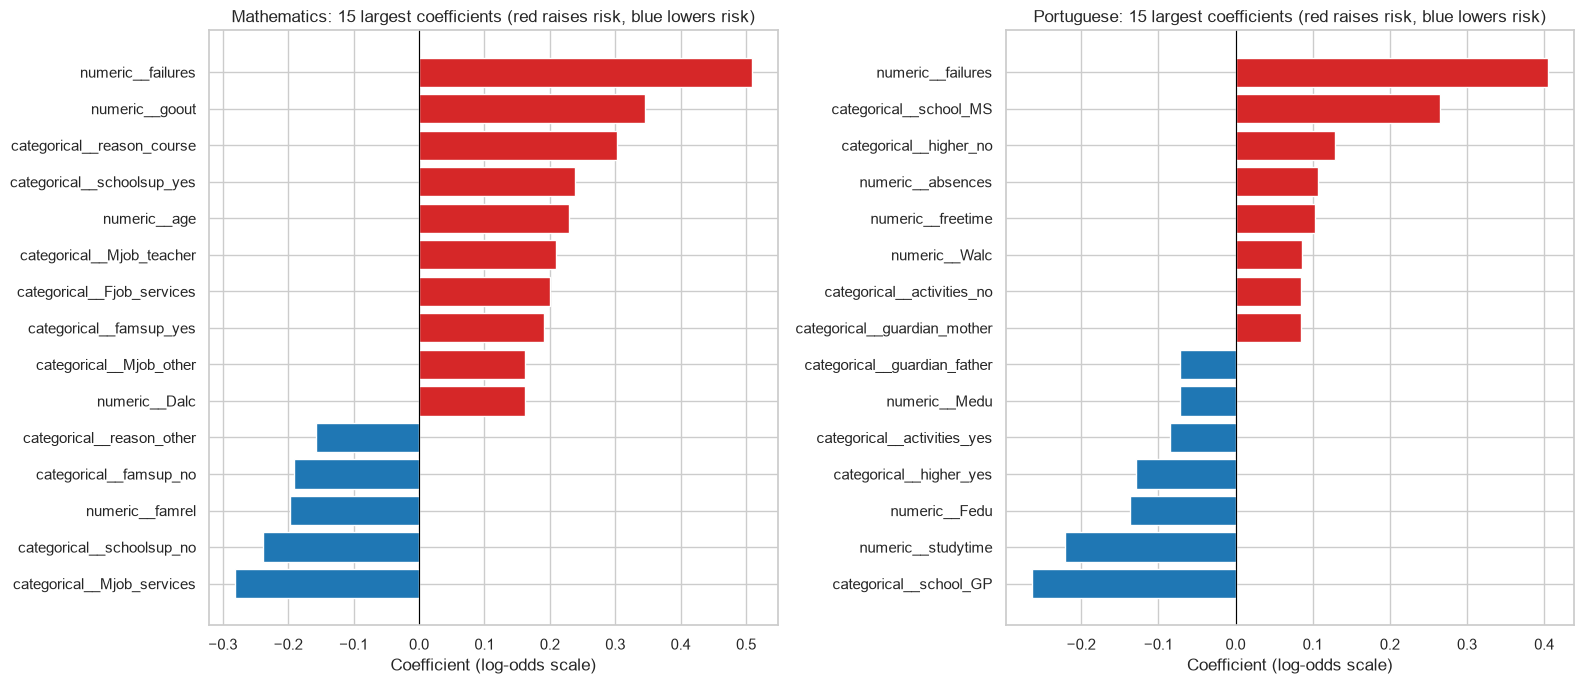


Mathematics: 10 largest coefficients


,Feature,Coefficient,Odds ratio,Direction
0,numeric__failures,0.5086,1.6629,raises risk
1,numeric__goout,0.3460,1.4133,raises risk
2,categorical__reason_course,0.3022,1.3529,raises risk
3,categorical__Mjob_services,-0.2813,0.7548,lowers risk
4,categorical__schoolsup_yes,0.2388,1.2698,raises risk
5,categorical__schoolsup_no,-0.2385,0.7878,lowers risk
6,numeric__age,0.2294,1.2579,raises risk
7,categorical__Mjob_teacher,0.2096,1.2332,raises risk
8,categorical__Fjob_services,0.2004,1.2219,raises risk
9,numeric__famrel,-0.1980,0.8204,lowers risk



Portuguese: 10 largest coefficients


,Feature,Coefficient,Odds ratio,Direction
0,numeric__failures,0.4052,1.4996,raises risk
1,categorical__school_MS,0.2644,1.3026,raises risk
2,categorical__school_GP,-0.2644,0.7677,lowers risk
3,numeric__studytime,-0.2216,0.8013,lowers risk
4,numeric__Fedu,-0.1366,0.8723,lowers risk
5,categorical__higher_no,0.1285,1.1371,raises risk
6,categorical__higher_yes,-0.1285,0.8794,lowers risk
7,numeric__absences,0.1067,1.1126,raises risk
8,numeric__freetime,0.1029,1.1084,raises risk
9,numeric__Walc,0.0858,1.0896,raises risk


In [22]:
def coefficient_table(model):
    """Coefficients and odds ratios with feature names taken from the fitted preprocessor."""
    names = model.named_steps["preprocessor"].get_feature_names_out()
    coefs = model.named_steps["classifier"].coef_[0]
    table = pd.DataFrame({"Feature": names, "Coefficient": coefs, "Odds ratio": np.exp(coefs)})
    table["Direction"] = np.where(table["Coefficient"] > 0, "raises risk", "lowers risk")
    table["Abs"] = table["Coefficient"].abs()
    return table.sort_values("Abs", ascending=False).drop(columns="Abs").reset_index(drop=True)

coefficient_tables = {s: coefficient_table(tuned_models[s]) for s in SUBJECTS}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, s in zip(axes, SUBJECTS):
    top = coefficient_tables[s].head(15).sort_values("Coefficient")
    ax.barh(top["Feature"], top["Coefficient"],
            color=["tab:red" if v > 0 else "tab:blue" for v in top["Coefficient"]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{s}: 15 largest coefficients (red raises risk, blue lowers risk)")
    ax.set_xlabel("Coefficient (log-odds scale)")
plt.tight_layout()
plt.show()

for s in SUBJECTS:
    print(f"\n{s}: 10 largest coefficients")
    display(coefficient_tables[s].head(10).round(4))

In [23]:
for s in SUBJECTS:
    table = coefficient_tables[s]
    up = table[table["Coefficient"] > 0].head(3)
    down = table[table["Coefficient"] < 0].head(3)
    print(f"{s}:")
    print("  Largest increases in risk odds: "
          + ", ".join(f"{r.Feature} (OR {r['Odds ratio']:.2f})" for _, r in up.iterrows()))
    print("  Largest decreases in risk odds: "
          + ", ".join(f"{r.Feature} (OR {r['Odds ratio']:.2f})" for _, r in down.iterrows()))

top10 = {s: coefficient_tables[s].head(10).set_index("Feature")["Coefficient"] for s in SUBJECTS}
shared = [f for f in top10["Mathematics"].index if f in top10["Portuguese"].index]
print("\nFeatures in both subjects' top 10 by absolute coefficient:",
      ", ".join(f"{f} ({'same' if np.sign(top10['Mathematics'][f]) == np.sign(top10['Portuguese'][f]) else 'opposite'} sign)"
                for f in shared) if shared else "none")
print("Reminder: these are associations learned by the model, not causal effects. OR = odds ratio.")

Mathematics:
  Largest increases in risk odds: numeric__failures (OR 1.66), numeric__goout (OR 1.41), categorical__reason_course (OR 1.35)
  Largest decreases in risk odds: categorical__Mjob_services (OR 0.75), categorical__schoolsup_no (OR 0.79), numeric__famrel (OR 0.82)
Portuguese:
  Largest increases in risk odds: numeric__failures (OR 1.50), categorical__school_MS (OR 1.30), categorical__higher_no (OR 1.14)
  Largest decreases in risk odds: categorical__school_GP (OR 0.77), numeric__studytime (OR 0.80), numeric__Fedu (OR 0.87)

Features in both subjects' top 10 by absolute coefficient: numeric__failures (same sign)
Reminder: these are associations learned by the model, not causal effects. OR = odds ratio.


## Step 10: Final results and recommendation

- **What are we doing?** Collecting baseline metrics, tuned metrics, best hyperparameters, the comparison and the coefficient insights into one report.
- **Why?** This is the section to read, present and copy into the group report. Every number comes from the cells above.
- **What does the code produce?** A summary per dataset, a computed interpretation, and the saved models and reports.
- **How to interpret it?** Read each dataset block separately, because the subjects are modelled independently and have different class balance. Test metrics, CV F1 and training information are labelled separately.

In [24]:
for s in SUBJECTS:
    best = tuning_df.set_index("Dataset").loc[s]
    print("=" * 72)
    print(f"{s.upper()}  |  Logistic Regression  |  held-out test set ({len(data[s]['y_test'])} students)")
    print("=" * 72)
    display(comparison_tables[s].round(4))
    print(f"Best hyperparameters: C={best['Best C']}, class_weight={best['Class Weight']}")
    print(f"Mean CV F1 (training folds only): tuned {best['Best CV F1']:.4f}, "
          f"baseline settings {best['Baseline CV F1 (C=1, no class weight)']:.4f}")
    ct = coefficient_tables[s]
    print("Strongest risk-raising features:", ", ".join(ct[ct["Coefficient"] > 0].head(3)["Feature"]))
    print("Strongest risk-lowering features:", ", ".join(ct[ct["Coefficient"] < 0].head(3)["Feature"]))
    print()

MATHEMATICS  |  Logistic Regression  |  held-out test set (79 students)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.6962,0.6835,-0.0127
At-Risk Precision,0.5714,0.5143,-0.0571
At-Risk Recall,0.3077,0.6923,0.3846
At-Risk F1,0.4000,0.5902,0.1902
ROC-AUC,0.7148,0.7315,0.0167


Best hyperparameters: C=0.1, class_weight=balanced
Mean CV F1 (training folds only): tuned 0.4895, baseline settings 0.4011
Strongest risk-raising features: numeric__failures, numeric__goout, categorical__reason_course
Strongest risk-lowering features: categorical__Mjob_services, categorical__schoolsup_no, numeric__famrel

PORTUGUESE  |  Logistic Regression  |  held-out test set (130 students)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.8462,0.80,-0.0462
At-Risk Precision,0.5000,0.40,-0.1000
At-Risk Recall,0.1500,0.60,0.4500
At-Risk F1,0.2308,0.48,0.2492
ROC-AUC,0.7659,0.79,0.0241


Best hyperparameters: C=0.01, class_weight=balanced
Mean CV F1 (training folds only): tuned 0.5082, baseline settings 0.3700
Strongest risk-raising features: numeric__failures, categorical__school_MS, categorical__higher_no
Strongest risk-lowering features: categorical__school_GP, numeric__studytime, numeric__Fedu



In [25]:
print("COMPUTED INTERPRETATION (generated from this run's results)\n")
for s in SUBJECTS:
    b, t = baseline_eval[s]["metrics"], tuned_eval[s]["metrics"]

    def winner(metric):
        return "tuned" if t[metric] > b[metric] else "baseline" if b[metric] > t[metric] else "neither (tie)"

    best_recall = max(b["At-Risk Recall"], t["At-Risk Recall"])
    print(f"{s}:")
    print(f"  Higher test F1: {winner('At-Risk F1')} (baseline {b['At-Risk F1']:.3f}, tuned {t['At-Risk F1']:.3f}).")
    print(f"  Higher test recall: {winner('At-Risk Recall')} (baseline {b['At-Risk Recall']:.3f}, tuned {t['At-Risk Recall']:.3f}).")
    print(f"  Higher test precision: {winner('At-Risk Precision')} (baseline {b['At-Risk Precision']:.3f}, tuned {t['At-Risk Precision']:.3f}).")
    print(f"  Higher test accuracy: {winner('Accuracy')} (baseline {b['Accuracy']:.3f}, tuned {t['Accuracy']:.3f}).")
    print(f"  ROC-AUC: baseline {b['ROC-AUC']:.3f}, tuned {t['ROC-AUC']:.3f}.")
    if best_recall < 0.5:
        print(f"  Warning: even the better model detects only {best_recall:.0%} of at-risk students, "
              "so it should not be the only screening tool.")
    else:
        print(f"  The better-recall model detects {best_recall:.0%} of at-risk students, at the cost of flagging "
              f"{int(confusion_matrix(data[s]['y_test'], (tuned_eval[s] if t['At-Risk Recall'] >= b['At-Risk Recall'] else baseline_eval[s])['y_pred'], labels=[0, 1])[0, 1])} not-at-risk students.")
    print()

COMPUTED INTERPRETATION (generated from this run's results)

Mathematics:
  Higher test F1: tuned (baseline 0.400, tuned 0.590).
  Higher test recall: tuned (baseline 0.308, tuned 0.692).
  Higher test precision: baseline (baseline 0.571, tuned 0.514).
  Higher test accuracy: baseline (baseline 0.696, tuned 0.684).
  ROC-AUC: baseline 0.715, tuned 0.731.
  The better-recall model detects 69% of at-risk students, at the cost of flagging 17 not-at-risk students.

Portuguese:
  Higher test F1: tuned (baseline 0.231, tuned 0.480).
  Higher test recall: tuned (baseline 0.150, tuned 0.600).
  Higher test precision: baseline (baseline 0.500, tuned 0.400).
  Higher test accuracy: baseline (baseline 0.846, tuned 0.800).
  ROC-AUC: baseline 0.766, tuned 0.790.
  The better-recall model detects 60% of at-risk students, at the cost of flagging 18 not-at-risk students.



### Strengths, limitations and responsible use

**Strengths**
- Logistic Regression is simple, fast and interpretable. It gives probabilities and coefficients that can be explained to educators.
- Preprocessing is fitted on training data only, the split is stratified and reproducible, and tuning never sees the test set.
- Evaluation reports precision, recall, F1 and ROC-AUC for the At-Risk class, not only accuracy.

**Limitations**
- The model is linear in the transformed features, so it cannot capture interactions or non-linear effects unless they are added by hand.
- The datasets are small, so the test set holds few at-risk students and the metrics are noisy. A single split does not show how much results vary.
- The decision threshold stays at 0.5, as in the original methodology. `class_weight` changes the trade-off between recall and precision, but a threshold chosen on validation data may do better. Do not choose a threshold on the test set.
- The data come from two Portuguese secondary schools, so results may not transfer to other schools or cohorts.
- Coefficients are associations. Several inputs describe family background and personal circumstances, and predictions based on them can reflect existing inequalities.

**Responsible use**
- Treat a prediction as a prompt for a supportive conversation, not as a label or a decision about a student.
- Validate on local data before real use, and check errors for groups that may be treated unfairly.
- The computed interpretation above is the evidence to cite in the assignment report. Check it against the tables before copying it.

### Save models and reports

Writes the fitted models and metric tables to `notebooks/models` and `notebooks/reports`. Set `SAVE_OUTPUTS = False` in Step 1 to skip. File names match the original notebook.

In [26]:
if SAVE_OUTPUTS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    REPORT_DIR.mkdir(parents=True, exist_ok=True)

    for s in SUBJECTS:
        joblib.dump(baseline_models[s], MODEL_DIR / f"logistic_regression_{s.lower()}.joblib")
        joblib.dump(tuned_models[s], MODEL_DIR / f"logistic_regression_{s.lower()}_tuned.joblib")
        coefficient_tables[s].to_csv(REPORT_DIR / f"logistic_regression_{s.lower()}_coefficients.csv", index=False)

    baseline_df.to_csv(REPORT_DIR / "logistic_regression_baseline.csv", index=False)
    tuned_out = tuned_df.merge(tuning_df[["Dataset", "Best CV F1", "Best C", "Class Weight"]], on="Dataset")
    tuned_out.to_csv(REPORT_DIR / "logistic_regression_tuned_metrics.csv", index=False)
    comparison_long.to_csv(REPORT_DIR / "logistic_regression_baseline_vs_tuned.csv", index=False)

    print("Saved models and reports to:")
    print(" ", MODEL_DIR.resolve())
    print(" ", REPORT_DIR.resolve())
else:
    print("SAVE_OUTPUTS is False: nothing was written.")

Saved models and reports to:
  C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\notebooks\models
  C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\notebooks\reports
